# Task 4: Random Forests & Ensembles

**Name:** Nurdaulet Zhussip  
**Course:** MOP 3231

In [1]:
import platform
import math

import matplotlib
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 2729

print(f"Python: {platform.python_version()}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"matplotlib: {matplotlib.__version__}")

Python: 3.12.0
NumPy: 2.3.4
pandas: 2.3.3
scikit-learn: 1.7.2
matplotlib: 3.10.7


In [2]:
tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

In [3]:
data = pd.read_csv("task-04-ML-course/data/spambase.csv")
print(f"Dataset shape: {data.shape}")
class_balance = data["spam"].value_counts(normalize=True).sort_index()
class_balance.index.name = "spam"
class_balance.name = "share"
display(class_balance.to_frame().round(4))

Dataset shape: (4204, 58)


,share
spam,
0,0.6013
1,0.3987


In [4]:
X = data.drop(columns="spam")
y = data["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=SEED,
)

print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}")
print(f"Training spam share: {y_train.mean():.4f}")
print(f"Test spam share: {y_test.mean():.4f}")

Training rows: 3153; test rows: 1051
Training spam share: 0.3987
Test spam share: 0.3987


In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Shared cross-validation folds: {cv.get_n_splits()}")

Shared cross-validation folds: 5


## Part 1

We will reconstruct the bagging model's out-of-bag mask and accuracy, compare all five fixed models on the same stratified folds, and compare the forest's OOB, CV, and held-out test estimates.

In [6]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask for rows absent from a bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=int)] = False
    return mask

In [7]:
tiny_expected = np.array([False, True, False, True, True])
tiny_result = oob_mask([0, 2, 2], 5)
empty_result = oob_mask([], 3)
array_result = oob_mask(np.array([3, 0]), 4)
print("Tiny example:", tiny_result, "matches:", np.array_equal(tiny_result, tiny_expected))
print("Empty sample:", empty_result, "matches:", np.array_equal(empty_result, [True, True, True]))
print("Array sample:", array_result, "matches:", np.array_equal(array_result, [False, True, True, False]))

Tiny example: [False  True False  True  True] matches: True
Empty sample: [ True  True  True] matches: True
Array sample: [False  True  True False] matches: True


For `oob_mask([0, 2, 2], 5)`, the result was `[False, True, False, True, True]`; it matched the expected mask. The empty-list and integer-array examples also matched (`True`).

In [8]:
bag.fit(X_train, y_train)
n_train = len(X_train)
oob_shares = np.array([
    oob_mask(indices, n_train).mean()
    for indices in bag.estimators_samples_
])
oob_formula = (1 - 1 / n_train) ** n_train
inbag_formula = 1 - oob_formula
print(f"Mean OOB share across {len(oob_shares)} trees: {oob_shares.mean():.4f}")
print(f"Mean in-bag share across trees: {1 - oob_shares.mean():.4f}")
print(f"Theoretical OOB share (1 - 1/n)^n: {oob_formula:.4f}")
print(f"Theoretical in-bag share: {inbag_formula:.4f}")

Mean OOB share across 100 trees: 0.3679
Mean in-bag share across trees: 0.6321
Theoretical OOB share (1 - 1/n)^n: 0.3678
Theoretical in-bag share: 0.6322


Across 100 trees, the mean OOB share was 0.3679 versus the theoretical 0.3678, and the mean in-bag share was 0.6321 versus 0.6322. With 3,153 training rows, the empirical and theoretical bootstrap shares closely agree.

In [9]:
votes = np.zeros((n_train, 2), dtype=int)
for estimator, sample_indices in zip(bag.estimators_, bag.estimators_samples_):
    mask = oob_mask(sample_indices, n_train)
    row_indices = np.flatnonzero(mask)
    predictions = estimator.predict(X_train.iloc[row_indices].to_numpy()).astype(int)
    votes[row_indices, predictions] += 1

own_oob_predictions = np.argmax(votes, axis=1)
own_oob_accuracy = np.mean(own_oob_predictions == y_train.to_numpy())
print(f"Own OOB accuracy: {own_oob_accuracy:.6f}")
print(f"bag.oob_score_: {bag.oob_score_:.6f}")
print("Exactly equal:", own_oob_accuracy == bag.oob_score_)
print(f"Absolute difference: {abs(own_oob_accuracy - bag.oob_score_):.12f}")

Own OOB accuracy: 0.934031
bag.oob_score_: 0.934031
Exactly equal: True
Absolute difference: 0.000000000000


The hand-built OOB accuracy was 0.934031 and `bag.oob_score_` was 0.934031; they were exactly equal (`True`, absolute difference 0). The vote counter and `argmax` implement the handout's OOB-only voting and class-0 tie rule.

In [10]:
models = {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}
fold_scores = {
    name: cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    for name, model in models.items()
}
cv_table = pd.DataFrame({name: scores for name, scores in fold_scores.items()},
                        index=[f"fold_{i}" for i in range(1, cv.get_n_splits() + 1)]).T
cv_table["mean"] = [fold_scores[name].mean() for name in cv_table.index]
cv_table["std"] = [fold_scores[name].std() for name in cv_table.index]
print("Accuracy by fold, mean, and population standard deviation:")
display(cv_table.round(4))

paired_differences = {
    "bag - tree": fold_scores["bag"] - fold_scores["tree"],
    "rf - tree": fold_scores["rf"] - fold_scores["tree"],
    "bag_lr - lr": fold_scores["bag_lr"] - fold_scores["lr"],
}
difference_table = pd.DataFrame(
    {name: {**{f"fold_{i + 1}": value for i, value in enumerate(values)},
            "mean": values.mean(), "std": values.std()}
     for name, values in paired_differences.items()}
).T
display(difference_table.round(4))
for name, differences in paired_differences.items():
    result = "inside the noise / no clear gain" if abs(differences.mean()) <= differences.std() else "outside the fold spread"
    print(f"{name}: mean difference={differences.mean():.4f}, std of differences={differences.std():.4f}; {result}.")

Accuracy by fold, mean, and population standard deviation:


,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
tree,0.8906,0.8891,0.9017,0.9175,0.9095,0.9017,0.0109
bag,0.9414,0.9113,0.9350,0.9444,0.9460,0.9356,0.0128
rf,0.9493,0.9208,0.9445,0.9571,0.9508,0.9445,0.0125
lr,0.9319,0.9192,0.9303,0.9413,0.9508,0.9347,0.0107
bag_lr,0.9366,0.9271,0.9303,0.9429,0.9556,0.9385,0.0101


,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
bag - tree,0.0507,0.0222,0.0333,0.0270,0.0365,0.0339,0.0097
rf - tree,0.0586,0.0317,0.0428,0.0397,0.0413,0.0428,0.0088
bag_lr - lr,0.0048,0.0079,0.0000,0.0016,0.0048,0.0038,0.0028


bag - tree: mean difference=0.0339, std of differences=0.0097; outside the fold spread.
rf - tree: mean difference=0.0428, std of differences=0.0088; outside the fold spread.
bag_lr - lr: mean difference=0.0038, std of differences=0.0028; outside the fold spread.


Bagging increased tree accuracy by a paired mean of 0.0339 (std of differences 0.0097), so the gain was outside the fold spread. Bagging logistic regression increased accuracy by 0.0038 (std 0.0028), also outside the spread, though the gain was smaller. Averaging bootstrap-fitted models can reduce variance; that effect is much larger for the high-variance tree than for the more stable logistic-regression pipeline.

In [11]:
rf.fit(X_train, y_train)
forest_cv_scores = fold_scores["rf"]
test_accuracy = rf.score(X_test, y_test)
test_se = np.sqrt(test_accuracy * (1 - test_accuracy) / len(y_test))
oob_cv_difference = abs(rf.oob_score_ - forest_cv_scores.mean())
oob_cv_agreement = oob_cv_difference <= forest_cv_scores.std()
print(f"Forest OOB accuracy: {rf.oob_score_:.4f}")
print(f"Forest CV mean +/- std: {forest_cv_scores.mean():.4f} +/- {forest_cv_scores.std():.4f}")
print(f"Absolute OOB-CV difference: {oob_cv_difference:.4f}")
print(f"OOB and CV agree by the handout's fold-spread rule: {oob_cv_agreement}")
print(f"Forest test accuracy: {test_accuracy:.4f} +/- {test_se:.4f} (standard error)")
print(f"Test set size: {len(y_test)}")

Forest OOB accuracy: 0.9489
Forest CV mean +/- std: 0.9445 +/- 0.0125
Absolute OOB-CV difference: 0.0044
OOB and CV agree by the handout's fold-spread rule: True
Forest test accuracy: 0.9524 +/- 0.0066 (standard error)
Test set size: 1051


The forest OOB score (0.9489) and CV mean (0.9445 ± 0.0125) differ by 0.0044, within the CV fold spread, so they agree by the handout's rule. Test accuracy was 0.9524 ± 0.0066 SE; it is 0.0035 above OOB and 0.0079 above the CV mean (about 1.2 test standard errors).

## Part 2

We evaluate the tree and forest on the held-out test data, choose a low-false-positive threshold from training out-of-fold probabilities only, then compare impurity and held-out permutation feature importances.

Decision tree ROC AUC: 0.8936; average precision: 0.8094
Random forest ROC AUC: 0.9868; average precision: 0.9822


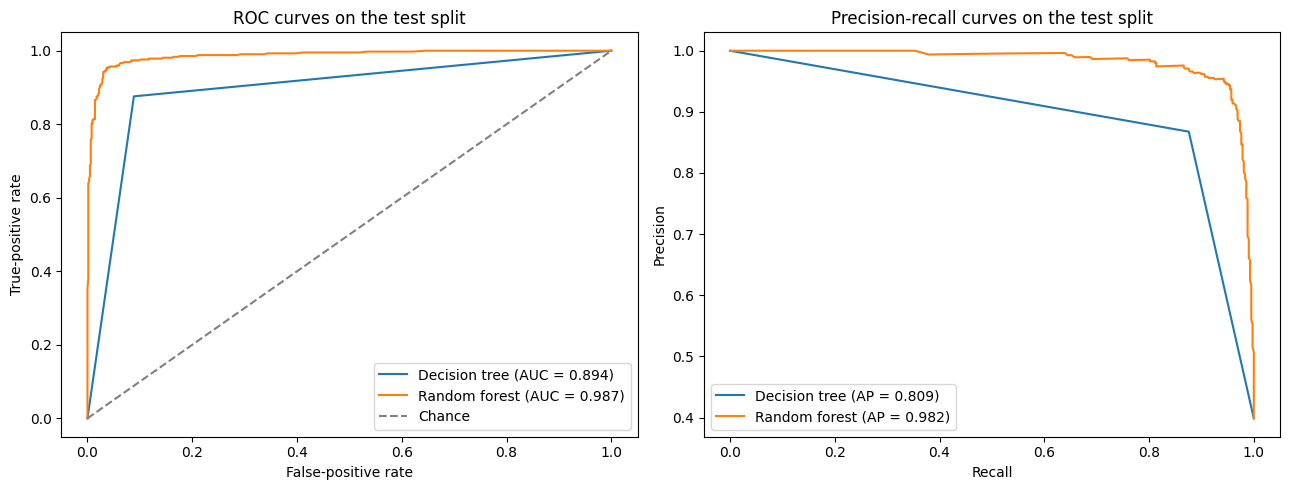

In [12]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_score,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import cross_val_predict

tree.fit(X_train, y_train)
rf.fit(X_train, y_train)
tree_test_probability = tree.predict_proba(X_test)[:, 1]
rf_test_probability = rf.predict_proba(X_test)[:, 1]

tree_auc = roc_auc_score(y_test, tree_test_probability)
rf_auc = roc_auc_score(y_test, rf_test_probability)
tree_ap = average_precision_score(y_test, tree_test_probability)
rf_ap = average_precision_score(y_test, rf_test_probability)
print(f"Decision tree ROC AUC: {tree_auc:.4f}; average precision: {tree_ap:.4f}")
print(f"Random forest ROC AUC: {rf_auc:.4f}; average precision: {rf_ap:.4f}")

tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_test_probability)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_test_probability)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(tree_fpr, tree_tpr, label=f"Decision tree (AUC = {tree_auc:.3f})")
axes[0].plot(rf_fpr, rf_tpr, label=f"Random forest (AUC = {rf_auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
axes[0].set(title="ROC curves on the test split", xlabel="False-positive rate", ylabel="True-positive rate")
axes[0].legend(fontsize=10)

tree_precision, tree_recall, _ = precision_recall_curve(y_test, tree_test_probability)
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_test_probability)
axes[1].plot(tree_recall, tree_precision, label=f"Decision tree (AP = {tree_ap:.3f})")
axes[1].plot(rf_recall, rf_precision, label=f"Random forest (AP = {rf_ap:.3f})")
axes[1].set(title="Precision-recall curves on the test split", xlabel="Recall", ylabel="Precision")
axes[1].legend(fontsize=10)
for axis in axes:
    axis.tick_params(labelsize=10)
    axis.title.set_fontsize(12)
fig.tight_layout()
plt.show()

On the test split, the tree had ROC AUC **0.8936** and average precision **0.8094**; the forest had ROC AUC **0.9868** and average precision **0.9822**.

In [13]:
oof_probability = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]
oof_fpr, oof_tpr, thresholds = roc_curve(
    y_train, oof_probability, drop_intermediate=False
)
eligible = np.flatnonzero(oof_fpr <= 0.01)
best_recall = oof_tpr[eligible].max()
best_candidates = eligible[oof_tpr[eligible] == best_recall]
threshold_index = best_candidates[np.argmax(thresholds[best_candidates])]
threshold = thresholds[threshold_index]
print(f"Threshold selected on training OOF probabilities: {threshold:.10f}")
print(f"Training OOF FPR at threshold: {oof_fpr[threshold_index]:.4f}")
print(f"Training OOF recall at threshold: {oof_tpr[threshold_index]:.4f}")

test_prediction_at_threshold = (rf_test_probability >= threshold).astype(int)
test_confusion = confusion_matrix(y_test, test_prediction_at_threshold, labels=[0, 1])
tn, fp, fn, tp = test_confusion.ravel()
test_precision = precision_score(y_test, test_prediction_at_threshold, zero_division=0)
test_recall = recall_score(y_test, test_prediction_at_threshold, zero_division=0)
test_fpr = fp / (fp + tn)
legitimate_test_count = fp + tn
test_fpr_se = np.sqrt(test_fpr * (1 - test_fpr) / legitimate_test_count)
print("Test confusion matrix (rows=true [0, 1], columns=predicted [0, 1]):")
print(test_confusion)
print(f"Test precision: {test_precision:.4f}")
print(f"Test recall: {test_recall:.4f}")
print(f"Test FPR: {test_fpr:.4f} +/- {test_fpr_se:.4f} (binomial standard error)")
print(f"Legitimate test emails flagged: {fp} out of {legitimate_test_count}")
print(f"The 1% FPR target held on test: {test_fpr <= 0.01}")

Threshold selected on training OOF probabilities: 0.7300000000
Training OOF FPR at threshold: 0.0095
Training OOF recall at threshold: 0.8178
Test confusion matrix (rows=true [0, 1], columns=predicted [0, 1]):
[[625   7]
 [ 79 340]]
Test precision: 0.9798
Test recall: 0.8115
Test FPR: 0.0111 +/- 0.0042 (binomial standard error)
Legitimate test emails flagged: 7 out of 632
The 1% FPR target held on test: False


The threshold was selected from training OOF probabilities only: `t = 0.73`, with OOF FPR 0.0095 and recall 0.8178. Applied once to test, the confusion matrix was `[[625, 7], [79, 340]]`; precision was 0.9798 and recall was 0.8115. The test FPR was 0.0111 (7 of 632 legitimate emails), with binomial SE 0.0042, so the 1% target did not hold on this test sample. The observed 1.11% FPR is just 0.11 percentage points above target, much smaller than its 0.42-point standard error; with only 632 legitimate test emails, the estimate has substantial sampling uncertainty.

In [14]:
permutation = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy"
)
permutation_importance_mean = pd.Series(permutation.importances_mean, index=X_train.columns)
impurity_importance = pd.Series(rf.feature_importances_, index=X_train.columns)
top_permutation = permutation_importance_mean.nlargest(5)
top_impurity = impurity_importance.nlargest(5)
importance_features = top_permutation.index.union(top_impurity.index)
importance_table = pd.DataFrame({
    "permutation_rank": permutation_importance_mean.rank(method="min", ascending=False).loc[importance_features].astype(int),
    "permutation_mean_accuracy_drop": permutation_importance_mean.loc[importance_features],
    "impurity_rank": impurity_importance.rank(method="min", ascending=False).loc[importance_features].astype(int),
    "impurity_importance": impurity_importance.loc[importance_features],
}).sort_values(["permutation_rank", "impurity_rank"])
print("Union of the top five features from each importance ranking:")
display(importance_table.round(5))

Union of the top five features from each importance ranking:


,permutation_rank,permutation_mean_accuracy_drop,impurity_rank,impurity_importance
word_freq_remove,1,0.03501,2,0.08783
word_freq_hp,2,0.02160,8,0.05074
char_freq_exclam,3,0.01912,1,0.11342
capital_run_length_average,4,0.01389,4,0.06761
word_freq_george,5,0.00980,13,0.02325
word_freq_free,6,0.00761,5,0.06402
char_freq_dollar,7,0.00742,3,0.08751


The union table includes the top five features from each ranking. `word_freq_george` ranks 5th by permutation importance but 13th by impurity importance: shuffling it reduces held-out accuracy by 0.00980, while the forest's accumulated training split importance is 0.02325. These measures differ because permutation importance measures held-out predictive reliance, whereas impurity importance sums training split improvements; correlated predictors can also share or substitute for predictive information.

## Part 3

We implement the handout's weighted majority vote, check it against scikit-learn hard voting, and compare individual members with hard and soft voting on the same cross-validation folds.

In [15]:
def hard_vote(predictions, weights=None):
    """Return the weighted majority class for each sample, breaking ties low."""
    predictions = np.asarray(predictions, dtype=int)
    n_models, n_samples = predictions.shape
    if weights is None:
        weights = np.ones(n_models, dtype=float)
    else:
        weights = np.asarray(weights)

    result = np.zeros(n_samples, dtype=int)
    for sample_index in range(n_samples):
        labels = np.unique(np.append(predictions[:, sample_index], 0))
        best_label = labels[0]
        best_count = 0
        for label in labels:
            count = 0
            for model_index in range(n_models):
                if predictions[model_index, sample_index] == label:
                    count += weights[model_index]
            if count > best_count:
                best_label = label
                best_count = count
        result[sample_index] = best_label
    return result

In [16]:
vote_examples = [
    (hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]), [0, 1, 0]),
    (hard_vote([[0, 1], [1, 0]]), [0, 0]),
    (hard_vote([[0, 1], [1, 0]], weights=[1, 2]), [1, 0]),
    (hard_vote([[2, 0], [2, 1], [0, 1]]), [2, 1]),
    (hard_vote([[1], [2]], weights=[0, 0]), [0]),
]
for number, (actual, expected) in enumerate(vote_examples, start=1):
    print(f"Example {number}: {actual}; matches expected: {np.array_equal(actual, expected)}")

Example 1: [0 1 0]; matches expected: True
Example 2: [0 0]; matches expected: True
Example 3: [1 0]; matches expected: True
Example 4: [2 1]; matches expected: True
Example 5: [0]; matches expected: True


The implementation follows model order when accumulating weights and uses strict comparisons, so exact ties go to the smallest label; when every weight is zero, label 0 wins. All handout examples, including labels above 1 and the all-zero-weight case, are checked above.

In [17]:
from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

member_test_predictions = np.array([
    clone(model).fit(X_train, y_train).predict(X_test)
    for _, model in members
])
own_hard_predictions = hard_vote(member_test_predictions)
hard_voter = VotingClassifier(members, voting="hard").fit(X_train, y_train)
sklearn_hard_predictions = hard_voter.predict(X_test)
hard_predictions_equal = np.array_equal(own_hard_predictions, sklearn_hard_predictions)
agreement_fraction = np.mean(own_hard_predictions == sklearn_hard_predictions)
print("Own hard_vote equals VotingClassifier predictions:", hard_predictions_equal)
print(f"Fraction of matching test predictions: {agreement_fraction:.4f}")

disagreements = []
for first in range(len(members)):
    for second in range(first + 1, len(members)):
        disagreements.append({
            "member_1": members[first][0],
            "member_2": members[second][0],
            "disagreement_rate": np.mean(member_test_predictions[first] != member_test_predictions[second]),
        })
disagreement_table = pd.DataFrame(disagreements)
display(disagreement_table.round(4))

Own hard_vote equals VotingClassifier predictions: True
Fraction of matching test predictions: 1.0000


,member_1,member_2,disagreement_rate
0,lr,knn,0.0485
1,lr,tree,0.1028
2,knn,tree,0.1265


The own `hard_vote` exactly reproduced `VotingClassifier(voting="hard")` on the test split (`True`; matching fraction 1.0000). Test disagreement rates were 0.0485 for LR vs KNN, 0.1028 for LR vs tree, and 0.1265 for KNN vs tree.

In [18]:
hard_voting = VotingClassifier(members, voting="hard")
soft_voting = VotingClassifier(members, voting="soft")
voting_models = {"lr": lr, "knn": knn, "tree": tree,
                 "hard voting": hard_voting, "soft voting": soft_voting}
voting_fold_scores = {
    name: cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy")["test_score"]
    for name, model in voting_models.items()
}
voting_cv_table = pd.DataFrame(
    {name: scores for name, scores in voting_fold_scores.items()},
    index=[f"fold_{i}" for i in range(1, cv.get_n_splits() + 1)],
).T
voting_cv_table["mean"] = [voting_fold_scores[name].mean() for name in voting_cv_table.index]
voting_cv_table["std"] = [voting_fold_scores[name].std() for name in voting_cv_table.index]
display(voting_cv_table.round(4))

member_means = {name: voting_fold_scores[name].mean() for name in ("lr", "knn", "tree")}
best_member = max(member_means, key=member_means.get)
print(f"Best single member by CV mean: {best_member} ({member_means[best_member]:.4f})")
paired_voting_differences = {}
for voter_name in ("hard voting", "soft voting"):
    differences = voting_fold_scores[voter_name] - voting_fold_scores[best_member]
    paired_voting_differences[voter_name] = differences
    judgement = "no winner / inside the noise" if abs(differences.mean()) <= differences.std() else (
        "voting is higher outside the fold spread" if differences.mean() > 0 else
        "best member is higher outside the fold spread"
    )
    print(f"{voter_name} - {best_member}: fold differences={np.round(differences, 4)}; "
          f"mean={differences.mean():.4f}, std={differences.std():.4f}; {judgement}.")

,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
lr,0.9319,0.9192,0.9303,0.9413,0.9508,0.9347,0.0107
knn,0.9113,0.9081,0.9208,0.9413,0.9063,0.9175,0.0129
tree,0.8906,0.8891,0.9017,0.9175,0.9095,0.9017,0.0109
hard voting,0.9319,0.9239,0.9398,0.9603,0.9460,0.9404,0.0124
soft voting,0.9350,0.9287,0.9319,0.9603,0.9460,0.9404,0.0116


Best single member by CV mean: lr (0.9347)
hard voting - lr: fold differences=[ 0.      0.0048  0.0095  0.019  -0.0048]; mean=0.0057, std=0.0082; no winner / inside the noise.
soft voting - lr: fold differences=[ 0.0032  0.0095  0.0016  0.019  -0.0048]; mean=0.0057, std=0.0081; no winner / inside the noise.


The best single member was LR (CV mean 0.9347). Hard voting's CV mean was 0.9404 and its paired difference from LR was `[0.0000, 0.0048, 0.0095, 0.0190, -0.0048]`, with mean 0.0057 and std 0.0082. Soft voting's CV mean was also 0.9404; its paired differences were `[0.0032, 0.0095, 0.0016, 0.0190, -0.0048]`, with mean 0.0057 and std 0.0081. For both ensembles, the mean gain is smaller than the paired-difference spread, so there is no winner / the differences are inside the noise.

## Part 4

We build stacking from out-of-fold spam probabilities, compare it with scikit-learn's stacking classifier, and contrast out-of-fold meta-learner weights with weights learned from in-sample predictions.

In [19]:
from sklearn.ensemble import StackingClassifier

oof_member_probabilities = np.column_stack([
    cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    for _, model in members
])
meta_learner = LogisticRegression()
meta_learner.fit(oof_member_probabilities, y_train)

test_member_probabilities = np.column_stack([
    clone(model).fit(X_train, y_train).predict_proba(X_test)[:, 1]
    for _, model in members
])
own_stack_predictions = meta_learner.predict(test_member_probabilities)
own_stack_accuracy = np.mean(own_stack_predictions == y_test.to_numpy())

stack = StackingClassifier(members, LogisticRegression(), cv=cv).fit(X_train, y_train)
stack_predictions = stack.predict(X_test)
stack_accuracy = stack.score(X_test, y_test)
coefficient_max_difference = np.max(np.abs(meta_learner.coef_ - stack.final_estimator_.coef_))
predictions_identical = np.array_equal(own_stack_predictions, stack_predictions)
print(f"Largest absolute meta-learner coefficient difference: {coefficient_max_difference:.12f}")
print("Own and sklearn test predictions identical:", predictions_identical)
print(f"Own OOF stacking test accuracy: {own_stack_accuracy:.4f}")
print(f"StackingClassifier test accuracy: {stack_accuracy:.4f}")

Largest absolute meta-learner coefficient difference: 0.000000000000
Own and sklearn test predictions identical: True
Own OOF stacking test accuracy: 0.9401
StackingClassifier test accuracy: 0.9401


The hand-built OOF stack's largest coefficient difference from `StackingClassifier` was 0.000000000000. The test predictions were identical (`True`), and both test accuracies were 0.9401.

In [20]:
in_sample_member_probabilities = np.column_stack([
    clone(model).fit(X_train, y_train).predict_proba(X_train)[:, 1]
    for _, model in members
])
naive_meta_learner = LogisticRegression().fit(in_sample_member_probabilities, y_train)
weight_table = pd.DataFrame({
    "in_sample_weight": naive_meta_learner.coef_[0],
    "oof_weight": meta_learner.coef_[0],
}, index=[name for name, _ in members])
display(weight_table.round(4))

,in_sample_weight,oof_weight
lr,1.9969,3.8693
knn,1.8595,2.8426
tree,8.2803,1.6023


The in-sample tree coefficient was 8.2803, compared with 1.6023 using OOF predictions. The unpruned tree nearly memorizes its in-sample training labels, so the naive meta-learner over-trusts it; OOF probabilities reveal the tree's weaker performance on unseen rows.

In [21]:
stacking_cv_scores = cross_validate(
    StackingClassifier(members, LogisticRegression(), cv=cv),
    X_train, y_train, cv=cv, scoring="accuracy",
)["test_score"]
soft_voting_cv_scores = voting_fold_scores["soft voting"]
best_member_cv_scores = voting_fold_scores[best_member]
stacking_comparison_scores = {
    "stacking": stacking_cv_scores,
    "soft voting": soft_voting_cv_scores,
    f"best member ({best_member})": best_member_cv_scores,
}
stacking_cv_table = pd.DataFrame(
    {name: scores for name, scores in stacking_comparison_scores.items()},
    index=[f"fold_{i}" for i in range(1, cv.get_n_splits() + 1)],
).T
stacking_cv_table["mean"] = [scores.mean() for scores in stacking_comparison_scores.values()]
stacking_cv_table["std"] = [scores.std() for scores in stacking_comparison_scores.values()]
display(stacking_cv_table.round(4))

stacking_differences = {
    f"stacking - best member ({best_member})": stacking_cv_scores - best_member_cv_scores,
    "stacking - soft voting": stacking_cv_scores - soft_voting_cv_scores,
}
stacking_difference_table = pd.DataFrame({
    **{f"fold_{i + 1}": [values[i] for values in stacking_differences.values()]
       for i in range(cv.get_n_splits())},
    "mean": [values.mean() for values in stacking_differences.values()],
    "std": [values.std() for values in stacking_differences.values()],
}, index=list(stacking_differences))
display(stacking_difference_table.round(4))
for name, differences in stacking_differences.items():
    result = "no winner / inside the noise" if abs(differences.mean()) <= differences.std() else (
        "stacking is higher outside the fold spread" if differences.mean() > 0 else
        "comparison model is higher outside the fold spread"
    )
    print(f"{name}: mean difference={differences.mean():.4f}, "
          f"std of differences={differences.std():.4f}; {result}.")

,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
stacking,0.9366,0.9334,0.9398,0.9556,0.9460,0.9423,0.0078
soft voting,0.9350,0.9287,0.9319,0.9603,0.9460,0.9404,0.0116
best member (lr),0.9319,0.9192,0.9303,0.9413,0.9508,0.9347,0.0107


,fold_1,fold_2,fold_3,fold_4,fold_5,mean,std
stacking - best member (lr),0.0048,0.0143,0.0095,0.0143,-0.0048,0.0076,0.0071
stacking - soft voting,0.0016,0.0048,0.0079,-0.0048,0.0000,0.0019,0.0043


stacking - best member (lr): mean difference=0.0076, std of differences=0.0071; stacking is higher outside the fold spread.
stacking - soft voting: mean difference=0.0019, std of differences=0.0043; no winner / inside the noise.


Stacking's CV mean was 0.9423 ± 0.0078, compared with 0.9347 ± 0.0107 for LR and 0.9404 ± 0.0116 for soft voting. The paired `stacking - LR` differences were `[0.0048, 0.0143, 0.0095, 0.0143, -0.0048]`, mean 0.0076 and std 0.0071, so stacking is higher outside the fold spread. The paired `stacking - soft voting` differences were `[0.0016, 0.0048, 0.0079, -0.0048, 0.0000]`, mean 0.0019 and std 0.0043, so there is no winner / the difference is inside the noise.

## Part 5

First we implement one AdaBoost weight update, reproduce the lecture example and check the fitted booster. Then we choose boosting rounds using training folds and measure how label noise affects three models.

### Step A: AdaBoost update, reproduction, and rounds

The helper below follows the handout's weighted-error and normalization rules. Round selection uses only the shared CV folds; the test learning curve is for comparison and reporting only.

In [22]:
def adaboost_step(y_true, y_pred, weights):
    """Return this learner's AdaBoost weight and normalized next row weights."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    new_weights = np.asarray(weights, dtype=float).copy()
    wrong = y_pred != y_true
    total_weight = new_weights.sum()
    error = new_weights[wrong].sum() / total_weight
    if error == 0:
        return math.inf, new_weights / total_weight
    alpha = math.log((1 - error) / error)
    new_weights[wrong] *= math.exp(alpha)
    new_weights /= new_weights.sum()
    return float(alpha), new_weights

In [23]:
step_examples = [
    ([1, 1, 0, 0], [1, 0, 0, 0], [1, 1, 1, 1], math.log(3), [1/6, 1/2, 1/6, 1/6]),
    ([1, 1, 1, 0], [0, 0, 0, 0], [1, 1, 1, 1], -math.log(3), [1/6, 1/6, 1/6, 1/2]),
    ([1, 0], [0, 0], [1, 1], 0.0, [0.5, 0.5]),
    ([1, 0, 1], [1, 0, 1], [2, 2, 4], math.inf, [0.25, 0.25, 0.5]),
    ([-1, 1, 1, -1], [-1, 1, -1, -1], [0.1, 0.2, 0.1, 0.1], math.log(4), [0.125, 0.25, 0.5, 0.125]),
]
for number, (y_true_example, y_pred_example, weights_example, expected_alpha, expected_weights) in enumerate(step_examples, 1):
    actual_alpha, actual_weights = adaboost_step(y_true_example, y_pred_example, weights_example)
    alpha_matches = actual_alpha == expected_alpha or np.isclose(actual_alpha, expected_alpha)
    weights_match = np.allclose(actual_weights, expected_weights)
    print(f"Example {number}: alpha={actual_alpha:.4f}, weights={np.round(actual_weights, 4)}; "
          f"alpha matches={alpha_matches}, weights match={weights_match}")

Example 1: alpha=1.0986, weights=[0.1667 0.5    0.1667 0.1667]; alpha matches=True, weights match=True
Example 2: alpha=-1.0986, weights=[0.1667 0.1667 0.1667 0.5   ]; alpha matches=True, weights match=True
Example 3: alpha=0.0000, weights=[0.5 0.5]; alpha matches=True, weights match=True
Example 4: alpha=inf, weights=[0.25 0.25 0.5 ]; alpha matches=True, weights match=True
Example 5: alpha=1.3863, weights=[0.125 0.25  0.5   0.125]; alpha matches=True, weights match=True


All five handout cases matched. In the lecture example, round errors were 0.300, 0.214, and 0.182, with alphas 0.847, 1.299, and 1.504; round 1 assigned about 0.071 to each correct row and 0.167 to each wrong row. Against scikit-learn, the largest alpha difference over five rounds was `3.33e-16`, the largest error difference was `5.55e-17`, and both comparisons were `allclose=True`.

In [24]:
x_toy = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
toy_stumps = [
    np.where(x_toy <= 3.5, 1, 0),
    np.where(x_toy <= 9.5, 1, 0),
    np.where(x_toy <= 6.5, 0, 1),
]
toy_weights = np.full(len(y_toy), 0.1)
toy_rows = []
for round_number, stump_prediction in enumerate(toy_stumps, start=1):
    weighted_error = toy_weights[stump_prediction != y_toy].sum() / toy_weights.sum()
    alpha, toy_weights = adaboost_step(y_toy, stump_prediction, toy_weights)
    toy_rows.append({
        "round": round_number,
        "error (ours)": weighted_error,
        "alpha (ours)": alpha,
        "weights (ours)": np.array2string(np.round(toy_weights, 3), separator=", ", max_line_width=120),
    })
display(pd.DataFrame(toy_rows).set_index("round"))
for row in toy_rows:
    print(f"Round {row['round']}: error={row['error (ours)']:.3f}, alpha={row['alpha (ours)']:.3f}, "
          f"weights={row['weights (ours)']}")
print("Lecture check: round 1 expected error=0.300, alpha=0.847, right-row weight=0.071, wrong-row weight=0.167.")

,error (ours),alpha (ours),weights (ours)
round,,,
1,0.300000,0.847298,"[0.071, 0.071, 0.071, 0.071, 0.071, 0.071, 0.1..."
2,0.214286,1.299283,"[0.045, 0.045, 0.045, 0.167, 0.167, 0.167, 0.1..."
3,0.181818,1.504077,"[0.125, 0.125, 0.125, 0.102, 0.102, 0.102, 0.0..."


Round 1: error=0.300, alpha=0.847, weights=[0.071, 0.071, 0.071, 0.071, 0.071, 0.071, 0.167, 0.167, 0.167, 0.071]
Round 2: error=0.214, alpha=1.299, weights=[0.045, 0.045, 0.045, 0.167, 0.167, 0.167, 0.106, 0.106, 0.106, 0.045]
Round 3: error=0.182, alpha=1.504, weights=[0.125, 0.125, 0.125, 0.102, 0.102, 0.102, 0.065, 0.065, 0.065, 0.125]
Lecture check: round 1 expected error=0.300, alpha=0.847, right-row weight=0.071, wrong-row weight=0.167.


Compare each printed round's weighted error, alpha, and weight vector with the three-stump lecture example; in particular, round 1 should have error 0.300, alpha 0.847, and normalized weights about 0.071 on correct rows and 0.167 on incorrect rows.

In [25]:
ada.fit(X_train.to_numpy(), y_train.to_numpy())
round_weights = np.full(len(y_train), 1 / len(y_train))
alpha_differences = []
error_differences = []
own_alphas = []
own_errors = []
for round_index, estimator in enumerate(ada.estimators_[:5]):
    stump_prediction = estimator.predict(X_train.to_numpy())
    weighted_error = round_weights[stump_prediction != y_train.to_numpy()].sum()
    own_alpha, round_weights = adaboost_step(y_train.to_numpy(), stump_prediction, round_weights)
    own_alphas.append(own_alpha)
    own_errors.append(weighted_error)
    alpha_differences.append(abs(own_alpha - ada.estimator_weights_[round_index]))
    error_differences.append(abs(weighted_error - ada.estimator_errors_[round_index]))
print(f"Largest alpha difference over first five rounds: {max(alpha_differences):.12g}")
print(f"Largest weighted-error difference over first five rounds: {max(error_differences):.12g}")
print("Round alphas allclose:", np.allclose(own_alphas, ada.estimator_weights_[:5]))
print("Round errors allclose:", np.allclose(own_errors, ada.estimator_errors_[:5]))

Largest alpha difference over first five rounds: 3.33066907388e-16
Largest weighted-error difference over first five rounds: 5.55111512313e-17
Round alphas allclose: True
Round errors allclose: True


The first five hand-built round updates are checked against scikit-learn's estimator weights and errors; the printed maximum differences quantify the match.

Round selected by mean training-fold accuracy: 296
Test error at CV-selected round: 0.0552
Best test-curve round (reported only): 300; test error: 0.0533
Absolute test-error difference: 0.0019
Test accuracy SE at CV-selected round: 0.0070
Test errors differ by more than this SE: False


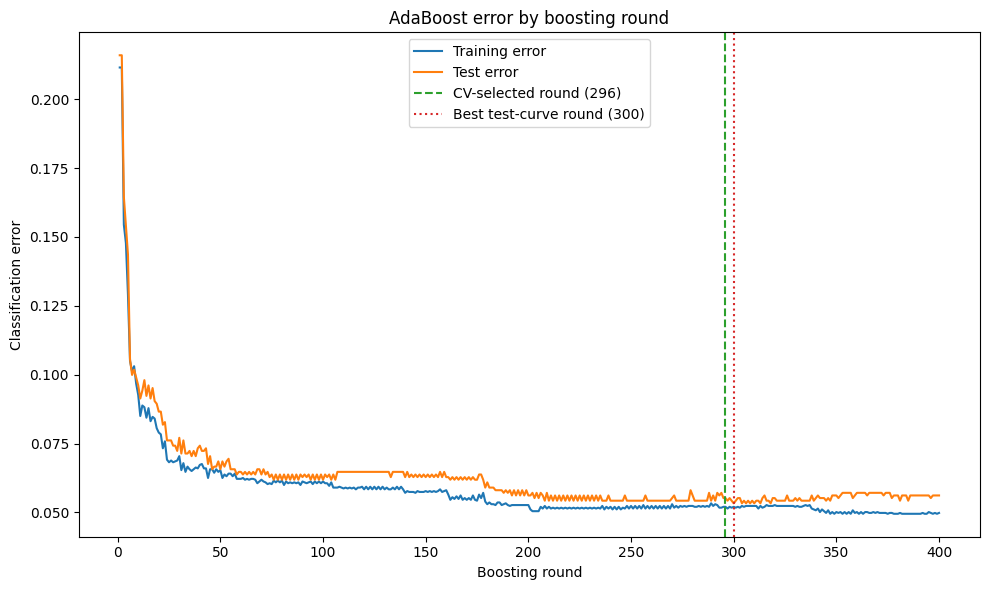

In [26]:
train_errors = 1 - np.asarray(list(ada.staged_score(X_train.to_numpy(), y_train.to_numpy())))
test_errors = 1 - np.asarray(list(ada.staged_score(X_test.to_numpy(), y_test.to_numpy())))
fold_accuracy_curves = []
for train_indices, validation_indices in cv.split(X_train, y_train):
    fold_ada = clone(ada).fit(X_train.iloc[train_indices].to_numpy(), y_train.iloc[train_indices].to_numpy())
    fold_accuracy_curves.append(list(fold_ada.staged_score(
        X_train.iloc[validation_indices].to_numpy(), y_train.iloc[validation_indices].to_numpy()
    )))
mean_fold_accuracy = np.mean(fold_accuracy_curves, axis=0)
chosen_round = int(np.argmax(mean_fold_accuracy)) + 1
best_test_round = int(np.argmin(test_errors)) + 1
chosen_test_error = test_errors[chosen_round - 1]
best_round_test_error = test_errors[best_test_round - 1]
chosen_test_accuracy = 1 - chosen_test_error
chosen_test_accuracy_se = np.sqrt(
    chosen_test_accuracy * (1 - chosen_test_accuracy) / len(y_test)
)
test_error_difference = abs(chosen_test_error - best_round_test_error)
print(f"Round selected by mean training-fold accuracy: {chosen_round}")
print(f"Test error at CV-selected round: {chosen_test_error:.4f}")
print(f"Best test-curve round (reported only): {best_test_round}; test error: {best_round_test_error:.4f}")
print(f"Absolute test-error difference: {test_error_difference:.4f}")
print(f"Test accuracy SE at CV-selected round: {chosen_test_accuracy_se:.4f}")
print("Test errors differ by more than this SE:", test_error_difference > chosen_test_accuracy_se)

rounds = np.arange(1, len(train_errors) + 1)
plt.figure(figsize=(10, 6))
plt.plot(rounds, train_errors, label="Training error")
plt.plot(rounds, test_errors, label="Test error")
plt.axvline(chosen_round, color="tab:green", linestyle="--",
            label=f"CV-selected round ({chosen_round})")
plt.axvline(best_test_round, color="tab:red", linestyle=":",
            label=f"Best test-curve round ({best_test_round})")
plt.title("AdaBoost error by boosting round")
plt.xlabel("Boosting round")
plt.ylabel("Classification error")
plt.tick_params(labelsize=10)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

CV selected round 296; its test error was 0.0552. The test curve's lowest error was 0.0533 at round 300. Their absolute difference was 0.0019, below the selected-round test-accuracy standard error of 0.0070, so these test errors are not meaningfully separated by that uncertainty.

### Step B: robustness to label noise

We flip only training labels, using five reproducible draws shared across the tree, forest, and 200-round AdaBoost model. All scores use the unchanged clean test labels.

In [27]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[indices] = 1 - y_noisy[indices]
    return y_noisy, indices

ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "forest": rf, "AdaBoost": ada200}
clean_test_accuracy = {}
for name, model in noise_models.items():
    clean_model = clone(model)
    if name == "AdaBoost":
        clean_model.fit(X_train.to_numpy(), y_train.to_numpy())
    else:
        clean_model.fit(X_train, y_train)
    clean_test_accuracy[name] = clean_model.score(
        X_test.to_numpy(), y_test.to_numpy()
    ) if name == "AdaBoost" else clean_model.score(X_test, y_test)

noise_draw_records = []
weight_share_records = []
for draw in range(5):
    y_noisy, flipped_indices = flip_labels(y_train.to_numpy(), 0.20, SEED + draw)
    for name, model in noise_models.items():
        fitted_model = clone(model)
        if name == "AdaBoost":
            fitted_model.fit(X_train.to_numpy(), y_noisy)
        else:
            fitted_model.fit(X_train, y_noisy)
        noisy_accuracy = fitted_model.score(
            X_test.to_numpy(), y_test.to_numpy()
        ) if name == "AdaBoost" else fitted_model.score(X_test, y_test)
        noise_draw_records.append({
            "draw": draw,
            "model": name,
            "test_accuracy": noisy_accuracy,
            "accuracy_loss": clean_test_accuracy[name] - noisy_accuracy,
        })

        if name == "AdaBoost":
            final_weights = np.full(len(y_train), 1 / len(y_train))
            for estimator in fitted_model.estimators_:
                _, final_weights = adaboost_step(
                    y_noisy, estimator.predict(X_train.to_numpy()), final_weights
                )
            weight_share_records.append({
                "draw": draw,
                "flipped_weight_share": final_weights[flipped_indices].sum(),
                "initial_flipped_share": len(flipped_indices) / len(y_train),
            })

noise_results = pd.DataFrame(noise_draw_records)
noise_summary = pd.DataFrame(index=list(noise_models))
noise_summary["clean_accuracy"] = pd.Series(clean_test_accuracy)
noise_summary["noisy_accuracy_mean"] = noise_results.groupby("model")["test_accuracy"].mean()
noise_summary["noisy_accuracy_std"] = noise_results.groupby("model")["test_accuracy"].agg(
    lambda values: np.std(values, ddof=0)
)
noise_summary["mean_accuracy_loss"] = noise_results.groupby("model")["accuracy_loss"].mean()
noise_summary["std_accuracy_loss"] = noise_results.groupby("model")["accuracy_loss"].agg(
    lambda values: np.std(values, ddof=0)
)
loss_by_draw = noise_results.pivot(index="draw", columns="model", values="accuracy_loss")
noise_summary["five_paired_losses"] = [
    np.round(loss_by_draw[name].to_numpy(), 4).tolist() for name in noise_summary.index
]
print("Clean accuracy (0% noise) and test accuracy / accuracy loss over five 20%-noise draws:")
display(noise_summary.round(4))

weight_share_table = pd.DataFrame(weight_share_records).set_index("draw")
print("AdaBoost final sample-weight share on flipped rows (initial share shown for comparison):")
display(weight_share_table.round(4))
print(f"Final flipped-row weight share: {weight_share_table['flipped_weight_share'].mean():.4f} "
      f"+/- {np.std(weight_share_table['flipped_weight_share'], ddof=0):.4f}")
print(f"Initial flipped-row share: {weight_share_table['initial_flipped_share'].mean():.4f}")

largest_loss_model = noise_summary["mean_accuracy_loss"].idxmax()
print(f"Largest mean accuracy loss: {largest_loss_model} "
      f"({noise_summary.loc[largest_loss_model, 'mean_accuracy_loss']:.4f} +/- "
      f"{noise_summary.loc[largest_loss_model, 'std_accuracy_loss']:.4f})")
for comparison_model in noise_summary.index:
    if comparison_model == largest_loss_model:
        continue
    paired_loss_difference = loss_by_draw[largest_loss_model] - loss_by_draw[comparison_model]
    difference_std = np.std(paired_loss_difference, ddof=0)
    result = "inside the noise / no clear ordering" if abs(paired_loss_difference.mean()) <= difference_std else "outside the paired spread"
    print(f"{largest_loss_model} loss - {comparison_model} loss: "
          f"mean={paired_loss_difference.mean():.4f}, std={difference_std:.4f}; {result}.")

Clean accuracy (0% noise) and test accuracy / accuracy loss over five 20%-noise draws:


,clean_accuracy,noisy_accuracy_mean,noisy_accuracy_std,mean_accuracy_loss,std_accuracy_loss,five_paired_losses
tree,0.8972,0.7262,0.0074,0.1711,0.0074,"[0.1713, 0.1808, 0.1579, 0.1732, 0.1722]"
forest,0.9524,0.9010,0.0025,0.0514,0.0025,"[0.0504, 0.0552, 0.0495, 0.0533, 0.0485]"
AdaBoost,0.9439,0.9132,0.0056,0.0306,0.0056,"[0.0304, 0.0371, 0.0219, 0.0362, 0.0276]"


AdaBoost final sample-weight share on flipped rows (initial share shown for comparison):


,flipped_weight_share,initial_flipped_share
draw,,
0,0.3980,0.2001
1,0.3903,0.2001
2,0.3984,0.2001
3,0.3920,0.2001
4,0.3965,0.2001


Final flipped-row weight share: 0.3950 +/- 0.0033
Initial flipped-row share: 0.2001
Largest mean accuracy loss: tree (0.1711 +/- 0.0074)
tree loss - forest loss: mean=0.1197, std=0.0060; outside the paired spread.
tree loss - AdaBoost loss: mean=0.1404, std=0.0034; outside the paired spread.


 The tree lost the most accuracy: `0.1711 ± 0.0074`, versus `0.0514 ± 0.0025` for the forest and `0.0306 ± 0.0056` for AdaBoost. Paired tree-minus-forest loss was `0.1197 ± 0.0060`, and tree-minus-AdaBoost loss was `0.1404 ± 0.0034`; both differences are outside their paired draw spreads. AdaBoost ended with `0.3950 ± 0.0033` of its sample weight on flipped rows, up from an initial share of `0.2001`, confirming it up-weighted many mislabeled/hard rows; however, in these draws it did not lose the most accuracy. The forest lost less than the single tree, consistent with averaging bootstrap-trained trees.